# Lava flow volume from DEM differencing

This notebook estimates mean lava-flow thickness, bulk and dense-rock equivalent volumes, and time-averaged discharge rates from digital elevation models (DEMs). It measures elevation change within a mapped lava-flow outline and uses the variability over surrounding stable terrain to estimate uncertainty.

This notebook updates the lava-volume workflow in [volcano_scripts](https://github.com/natturufraedistofnun/volcano_scripts). The main change is the use of [xDEM](https://xdem.readthedocs.io) to coregister the DEMs over stable terrain. The example uses a pre-eruption DEM and the 11 July 2023 survey of the Litli Hrútur eruption on Iceland’s Reykjanes Peninsula.

## Run the example

Install Miniconda if you do not already have it. [Find your install guide](https://www.anaconda.com/docs/getting-started/installation)

Keep the notebook, `requirements.txt`, and the input files in the same directory. Open a terminal there (use Miniconda Prompt on Windows) and run these commands to set up the tested Python version and launch JupyterLab.

```sh
conda create --name lava-volume --channel conda-forge --override-channels python=3.14 pip
conda activate lava-volume
python -m pip install -r requirements.txt
python -m jupyterlab
```

Open `lava_volume_calculation.ipynb` in JupyterLab, select the Python 3 kernel from the `lava-volume` environment, and run all cells.

The example uses 2 m DEMs in ISN93 (EPSG:3057), with elevations in ISH2004 (EPSG:8089). It also uses a mapped lava outline and two masks for survey reconstruction artifacts. The bundled orthomosaic provides visual context. The example also includes a polygon of lava emplaced between two surveys.

The notebook writes the aligned survey DEM, elevation difference rasters, and a text summary to `output/`. It also plots a thickness histogram.

In [1]:
import math
from datetime import datetime, timezone
from pathlib import Path

import geoutils as gu
import matplotlib.pyplot as plt
import numpy as np
import xdem

plt.rcParams["axes.formatter.useoffset"] = True
plt.rcParams["axes.formatter.offset_threshold"] = 2

## Survey interval and prior volumes

Use a consistent time zone for both timestamps. In this notebook, times are in UTC. A survey time is usually the midpoint of the survey, halfway between its start and end.

- **First calculation of an eruption.** Set `t1` to the eruption start date and time and `t2` to the first survey's date and time. Set both prior volumes to zero and leave `new_lava_filename` set to `None`.
- **Second or later survey.** Set `t1` to the previous survey's date and time and `t2` to the current survey's date and time. Enter the previous survey's cumulative bulk and dense-rock equivalent (DRE) volumes in cubic metres. Set `new_lava_filename` to the polygon file for lava emplaced between those two surveys.

The settings below illustrate the first calculation. The [Icelandic Meteorological Office](https://en.vedur.is/volcanoes/fagradalsfjall-eruption/news-and-alerts/earthquake-activity-in-fagradalsfjall-area) reports the eruption onset at 16:40 UTC on 10 July 2023. The example survey time is 18:00 UTC on 11 July.

In [2]:
t1 = datetime(2023, 7, 10, 16, 40, tzinfo=timezone.utc)
t2 = datetime(2023, 7, 11, 18, 0, tzinfo=timezone.utc)
vol_prevDEM = 0
vol_prevDEM_dre = 0

## File locations

Use the full mapped lava outline to estimate cumulative volume at `t2`. For a second or later survey, also supply a polygon showing where additional lava was emplaced since `t1`. It can include both newly covered ground and areas where new lava overlies earlier flows. This polygon supplies the area used to estimate the uncertainty in the interval's volume change and discharge rate. The volume emplaced during the interval is calculated by subtracting the cumulative volume at `t1` from the cumulative volume at `t2`.

In [ ]:
# vector layer containing polygons of the lava field
lava_filename = Path("20230711_1800_lava_outline.gpkg")
# vector layer containing polygons covering artifacts in the DEM reconstruction
artifact_filename = Path("20230711_1800_artifact_mask.gpkg")
# the pre-eruption DEM to align the survey DEM to
dem_pre_filename = Path("20220821_pre-eruption_DEM_2m_zmae.tif")
# the survey DEM to be aligned
dem_tba_filename = Path("20230711_1800_DEM_2m_ISN93.tif")
# vector layer containing polygons covering any lava channels that need interpolating over
channel_filename = Path("20230711_1800_channel_mask.gpkg")
# vector layer containing polygons showing areas of lava that have been emplaced since the previous survey
# if first calculation leave as None to use the full mapped lava area for uncertainty.
# e.g. Path("2023-07-11_1800_new_lava.gpkg").
new_lava_filename = None

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

## Load lava outline for mask and plotting

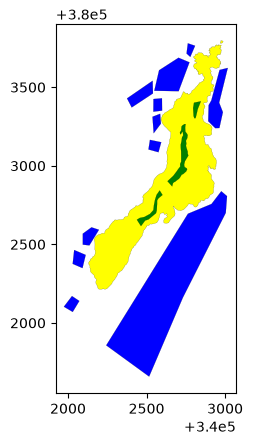

In [4]:
lava_outline = gu.Vector(lava_filename)
artifacts_layer = gu.Vector(artifact_filename)
channel_layer = gu.Vector(channel_filename)
new_lava_outline = gu.Vector(new_lava_filename) if new_lava_filename is not None else None

artifacts_layer.plot(fc="blue", ec="k", lw=0.1, label="Reconstruction artifacts")
lava_outline.plot(fc="yellow", ec="k", lw=0.1, label="Lava outline")
channel_layer.plot(fc="green", ec="k", lw=0.1, label="Channel artifacts")

## Load the DEMs and put them on the reference grid

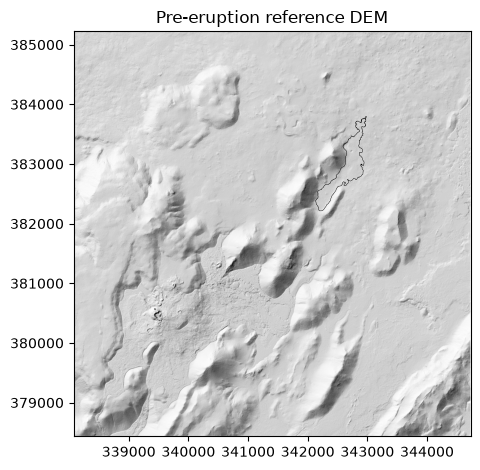

In [5]:
reference_vcrs = 8089
survey_vcrs = 8089

dem_pre = xdem.DEM(dem_pre_filename, vcrs=reference_vcrs, nodata=-9999)
dem_tba = xdem.DEM(dem_tba_filename, vcrs=survey_vcrs, nodata=-9999)
if survey_vcrs != reference_vcrs:
    dem_tba = dem_tba.to_vcrs(reference_vcrs)
dem_tba = dem_tba.reproject(dem_pre)

dem_pre.hillshade().plot(cmap="Greys_r", add_cbar=False, title="Pre-eruption reference DEM")
lava_outline.plot(fc="none", ec="k", lw=0.3)

## Mask out artifacts in survey DEM

In [6]:
inside_lava = lava_outline.create_mask(dem_pre)
stable_terrain = ~inside_lava
artifact_mask = artifacts_layer.create_mask(dem_pre)

dem_tba_masked = dem_tba.copy()
dem_tba_masked[artifact_mask] = np.nan
dem_tba_masked.to_file(output_dir / f"{dem_tba_filename.stem}_masked.tif")

## Find elevation difference prior to alignment

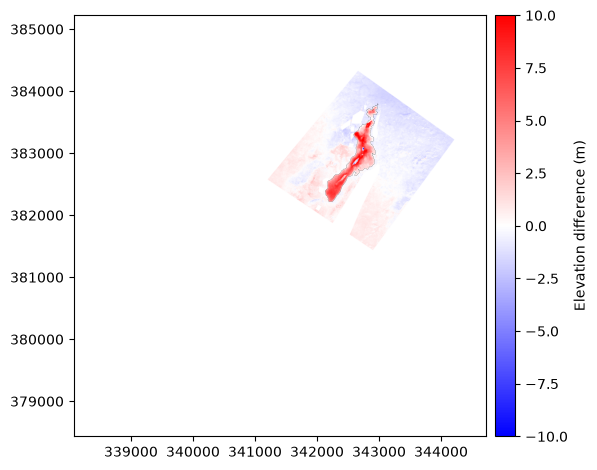

In [7]:
ddem_initial = dem_tba_masked - dem_pre
ddem_initial.plot(cmap="bwr", vmin=-10, vmax=10, cbar_title="Elevation difference (m)")
lava_outline.plot(fc="none", ec="k", lw=0.1)
ddem_initial.to_file(output_dir / f"{dem_tba_filename.stem}_ddem.tif")

## Coregister the survey DEM over stable terrain

Fit the xDEM Nuth and Kääb and LZD steps on valid terrain outside the mapped lava outline. Use a fixed sampling seed so the example can be rerun.

In [8]:
coreg_pipeline = xdem.coreg.NuthKaab() + xdem.coreg.LZD()
coreg_pipeline.fit(dem_pre, dem_tba_masked, stable_terrain, random_state=42)
dem_align = coreg_pipeline.apply(dem_tba_masked)
dem_align.set_vcrs(reference_vcrs)
dem_align.to_file(output_dir / f"{dem_tba_filename.stem}_align.tif")

## Calculate difference of aligned survey

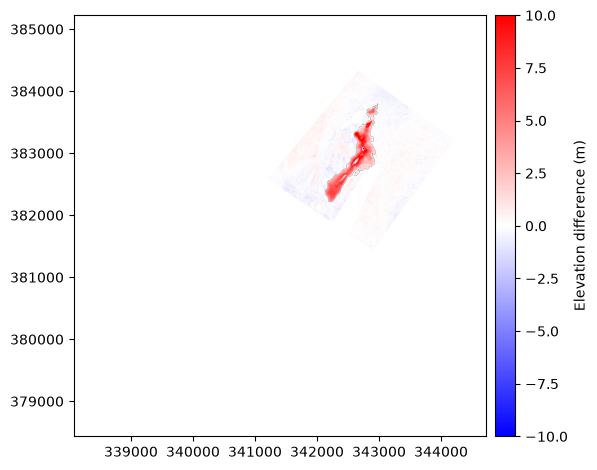

In [9]:
ddem_after = dem_align - dem_pre
ddem_after.plot(cmap="bwr", vmin=-10, vmax=10, cbar_title="Elevation difference (m)")
lava_outline.plot(fc="none", ec="k", lw=0.1)
ddem_after.to_file(output_dir / f"{dem_tba_filename.stem}_align_dh.tif")

## Mask out channel artifacts

In [10]:
channel_mask = channel_layer.create_mask(dem_pre).data
dh = ddem_after.data.filled(np.nan)
channel_gaps = channel_mask & np.isfinite(dh)
dh_masked = np.where(channel_gaps, np.nan, dh)

## Fill mapped channel gaps

Use inverse-distance weighting with a search radius of 30 pixels (60 m on this grid). Keep interpolated values only where the channel mask removed valid data. Existing gaps in the aligned DEM difference remain masked.

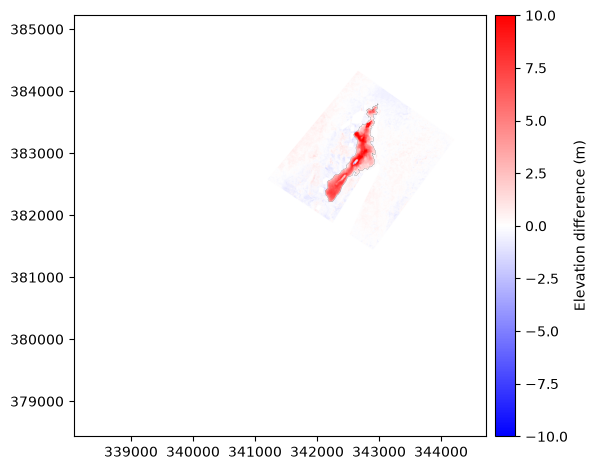

In [11]:
interpolated = xdem.volume.idw_interpolation(
    dh_masked,
    max_search_distance=30,
    extrapolate=False,
    force_fill=False,
)
ddem_idw = ddem_after.copy()
ddem_idw.data = np.ma.masked_invalid(np.where(channel_gaps, interpolated, dh))
ddem_idw.to_file(output_dir / f"{dem_tba_filename.stem}_align_dh_fill.tif")
ddem_idw.plot(cmap="bwr", vmin=-10, vmax=10, cbar_title="Elevation difference (m)")
lava_outline.plot(fc="none", ec="k", lw=0.1)

## Estimate thickness, volume, and time-averaged discharge rate

Subtract the median elevation change over stable terrain from the mean change inside the lava outline. The mean uses all valid elevation differences, including zero and negative values. Multiply this bias-corrected mean thickness by the mapped lava area to estimate bulk volume. The normalized median absolute deviation (NMAD) over stable terrain is used as the thickness uncertainty and scaled by area for volume uncertainty. Discharge is the change in cumulative volume divided by the survey interval. The DRE estimates include uncertainty in the bulk-to-DRE conversion factor (0.75 ± 0.25).

In [12]:
log_lines = []
def log(msg=""):
    print(msg)
    log_lines.append(str(msg))

delta_t = (t2 - t1).total_seconds()
if delta_t <= 0:
    raise ValueError("The survey interval must be greater than zero.")

log("\n###############################")
log("### Lava volume & TADR calc ###")
log(f"### t1: {t1} ###")
log(f"### t2: {t2} ###")
log("###############################\n")

lava_area = lava_outline.ds.area.sum()
interval_lava_area = new_lava_outline.ds.area.sum() if new_lava_outline is not None else lava_area
log(f"Area used for uncertainty in volume change: {interval_lava_area / 1e6:.3f} km²")

stable_vals = ddem_idw[stable_terrain].compressed()
lava_vals = ddem_idw[inside_lava].compressed()
if not stable_vals.size or not lava_vals.size:
    raise ValueError("The elevation difference raster must cover both stable terrain and lava.")
med_stable = np.median(stable_vals)
nmad_stable = gu.stats.nmad(stable_vals)

log(f"Median & NMAD of surrounding areas: {med_stable:.3f} m ± {nmad_stable:.3f} m")

unc_delta_vol = interval_lava_area * nmad_stable

log(f"Uncertainty of deltaVol: {unc_delta_vol/1e6:.3f} million m³")
log(f"Lava volume t1 (Bulk): {vol_prevDEM} m³")
log(f"Lava volume t1 (DRE): {vol_prevDEM_dre} m³")


lava_thickness = lava_vals - med_stable
avg_dh = np.mean(lava_thickness)
log(f"Valid elevation differences inside lava outline: {lava_vals.size / np.count_nonzero(inside_lava.data):.1%}")

vol_bulk = lava_area * avg_dh
unc_vol_bulk = lava_area * nmad_stable

tadr_bulk = (vol_bulk - vol_prevDEM) / delta_t
unc_tadr_bulk = unc_delta_vol / delta_t

log(f"\nArea of lavas: {lava_area/1e+6:.2f} km²")
log(f"Mean lava thickness: {avg_dh:.1f} ± {nmad_stable:.1f} m")
log(f"Lava volume (Bulk): {vol_bulk / 1e6:.2f} ± {unc_vol_bulk / 1e6:.2f} million m³")
log(f"Lava volume full: {int(vol_bulk)} ± {int(unc_vol_bulk)} m³")
log(f"TADR (bulk): {tadr_bulk:.1f} ± {unc_tadr_bulk:.1f} m³/s")

c = 0.75
unc_c = 0.25

vol_dre = vol_bulk * c
unc_vol_dre = np.sqrt((c * unc_vol_bulk) ** 2 + (vol_bulk * unc_c) ** 2)

tadr_dre = (vol_dre - vol_prevDEM_dre) / delta_t
unc_tadr_dre = np.sqrt(
    (c / delta_t * unc_delta_vol) ** 2
    + (((vol_bulk - vol_prevDEM) / delta_t) * unc_c) ** 2
)

log(f"\nLava volume (DRE*): {vol_dre/1e+6:.1f} ± {unc_vol_dre/1e+6:.1f} million m³")
log(f"Lava volume full dre: {int(vol_dre)} ± {int(unc_vol_dre)} m³")
log(f"TADR (DRE*): {tadr_dre:.1f} ± {unc_tadr_dre:.1f} m³/s")
log(f"*Conversion factor from bulk volume to DRE: {c} ± {unc_c} ")

summary_path = output_dir / f"{t2.strftime('%Y%m%d_%H%M')}_summary.txt"
with summary_path.open("w", encoding="utf-8") as summary_file:
    print("\n".join(log_lines), file=summary_file)


###############################
### Lava volume & TADR calc ###
### t1: 2023-07-10 16:40:00+00:00 ###
### t2: 2023-07-11 18:00:00+00:00 ###
###############################

Area used for uncertainty in volume change: 0.362 km²
Median & NMAD of surrounding areas: 0.021 m ± 0.271 m
Uncertainty of deltaVol: 0.098 million m³
Lava volume t1 (Bulk): 0 m³
Lava volume t1 (DRE): 0 m³
Valid elevation differences inside lava outline: 100.0%

Area of lavas: 0.36 km²
Mean lava thickness: 4.8 ± 0.3 m
Lava volume (Bulk): 1.72 ± 0.10 million m³
Lava volume full: 1724127 ± 98141 m³
TADR (bulk): 18.9 ± 1.1 m³/s

Lava volume (DRE*): 1.3 ± 0.4 million m³
Lava volume full dre: 1293095 ± 437271 m³
TADR (DRE*): 14.2 ± 4.8 m³/s
*Conversion factor from bulk volume to DRE: 0.75 ± 0.25 


## Histogram of lava thickness in final DDEM

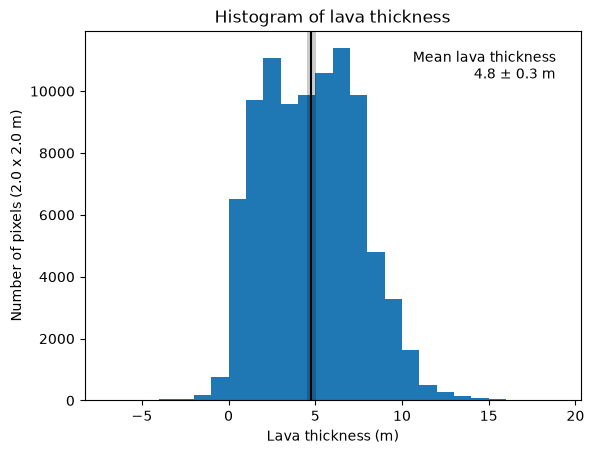

In [13]:
fig, ax = plt.subplots()
ax.hist(lava_thickness,
        bins=np.arange(
            math.floor(lava_thickness.min()),
            math.ceil(lava_thickness.max()) + 2,
            1)
       )
ax.axvspan(avg_dh-nmad_stable, avg_dh+nmad_stable, fc="k", alpha=0.2, lw=5)
ax.axvline(avg_dh, c="k")
ax.text(
    0.95,
    0.95,
    f"Mean lava thickness\n{avg_dh:.1f} ± {nmad_stable:.1f} m",
    transform=ax.transAxes,
    ha="right",
    va="top",
)
ax.set_title("Histogram of lava thickness")
ax.set_xlabel("Lava thickness (m)")
ax.set_ylabel(f"Number of pixels ({ddem_idw.res[0]} x {ddem_idw.res[1]} m)")
plt.show()